# openpilot supercombo on KITScenes: one scene, every keyframe

The benchmark scores each scene only at the keyframes its shared sample list names: 40, 130, 220, and so on, 9 s apart. The [image-tweak notebook](openpilot_drv_supcombo_kitscenes_image_tweak.ipynb) knows only those keyframes, which is why `FOCUS = "dbba76d9/150"` raises a `KeyError` there. Frame 150 is in the scene, but no listed sample starts at it.

This notebook makes every frame of one scene a keyframe and runs openpilot on each, built the way the list builds its own rows (the route is read from where the car is 5 s later; more than 5 m to a side counts as a turn). For each keyframe it gives:

1. **The route**, read by the list's rule, beside the listed rows. On the listed keyframes the two must agree.
2. **Every score and every head of the model.** ADE, FDE, lateral and longitudinal error, heading, speed, the camera height the model reads, desire, lead, lane lines and plan sigma. Each comes with a noise floor: the largest change that any of eight half-pixel shifts of the image makes.
3. **A check that "stock here" is the recorded model**, on the listed keyframes.
4. **A timeline** of all of the above across the scene.
5. **Every keyframe's figure**, written as JPEG to a cache directory outside the repo.
6. **A frame-by-frame view**: one keyframe's figure and the score rows around it.

Each keyframe is its own 4.8 s replay from a reset model, the way the benchmark scores it; it is not one continuous drive. Keyframes k and k + 1 share 47 of their 48 history frames. A jump between them is the model's response to one more frame, not state carried over.

The code is in [the sweep lib](openpilot_drv_supcombo_kitscenes_scene_sweep_lib.py). It is the image-tweak lab with more keyframes: it is imported, not copied, so what a `CONFIG` does to the image is defined in one place. It runs only stock unless `CONFIG` is set.

In [1]:
import sys

import pandas as pd

from paddock.config import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT / "tools/models/openpilot/analysis"))  # the libs, beside this notebook
import openpilot_drv_supcombo_image_tweak_lib as T
import openpilot_drv_supcombo_kitscenes_scene_sweep_lib as S

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 200)

## 1. Parameters

- **`SCENE`**: a scene id, or a unique prefix of one.
- **`START`, `STOP`, `STRIDE`**: the keyframes, as source frame indices at 10 Hz.
    - `STOP = None` means the last keyframe with the benchmark's full 4 s of GT (8 poses at 0.5 s).
    - Keyframes from 40 frames before that point onward read their route less than 5 s ahead, because the scene ends first. The `lookahead_s` column says how far ahead it was read.
- **`RUN_ID`**: the recorded stock run that part 3 checks against.
- **`DEVICE`**: `"cuda"` or `"cpu"`.
    - Either costs about 1 s per replay. Measured on the same 16 keyframes: a median of 1.0 s on a GPU and 1.1 s on the CPU. The time goes to the 98 ticks of frame preparation, which run on the CPU either way.
    - `"cuda"` is the default because the recorded run was made on a GPU, so part 3's check can be exact.
    - The GPUs are shared, so check `nvidia-smi` first. Each node takes well under 1 GB.
- **`NODES`**: the number of model processes. Keyframes are split into contiguous blocks, one per node, so each node decodes its frames once.
- **`HEIGHT`, `OVERRIDES`, `RECOMPUTE`**: as in the image-tweak notebook.
- **`CONFIG`**: `None` runs stock. Otherwise give a dict of the image-tweak knobs; it is run beside stock, or beside `AGAINST`, on every keyframe.
- **`OVERLAY`**: where the GT and plans are drawn in each keyframe's figure: `"img"`, `"big_img"`, `"camera"`.
- **`WIDGETS`**: a slider in part 6. It is off by default because VS Code cannot draw a saved widget.
- **`WORKERS`**: the processes that draw the figures in part 5.

In [2]:
SCENE = "dbba76d9-91ec-b44f-f3d3-6348d55f7849"  # the "not planned" left turn of the image-tweak notebook
START, STOP, STRIDE = 40, None, 1
RUN_ID = "20260930T154018-242869"  # the open-loop notebook's stock re-run
DEVICE = "cuda"  # as fast as "cpu" here, and the recorded run's device
NODES, THREADS = 16, 8  # the speed is in the nodes: ~1 s a replay each, ~7 GB of frames each
HEIGHT = "context"
OVERRIDES = {}
RECOMPUTE = False
CONFIG = None  # e.g. dict(pitch_deg=-1.7, desire="turn"); None runs stock alone
CONFIG = dict(
    # geometry
    height_scale=1.22,  # s: the road as from a camera at h / s
    zoom=1.0,  # k: magnified k x
    hstretch=1.0,  # g: stretched g x sideways
    yaw_deg=0.0,  # the view turned left (deg)
    turn_yaw_deg=0.0,  # the view turned toward the route's side (deg); negative is away
    pitch_deg=-1.7,  # the view tilted up (deg)
    roll_deg=0.0,  # the view rolled, its right side down (deg)
    ahead_m=0.0,  # the camera moved forward (m)
    left_m=0.0,  # and left (m)
    dx_px=0.0,  # the sampling grid moved right (model pixels)
    dy_px=0.0,  # 30.0,  # and down
    views="both",  # where the geometry applies: "both", "img" or "big_img"
    # sampling
    supersample=1,  # n: n x n camera samples per model pixel
    ss_views="big_img",  # where supersampling applies
    sharpen=0.0,  # alpha; -1 is a 3 x 3 blur
    # tone, on both views
    gamma=1.0,  # on luma; under 1 is brighter
    contrast=1.0,  # about mid-grey
    brightness=0.0,  # luma steps
    saturation=1.0,  # 0 is grey
    # ablation
    blank="",  # "img" or "big_img": that view shown as flat grey
    # the source
    camera="base",  # "ring" (stock) or "base"
    fov_deg=55.0,  # cut the frame to this many degrees across; T.EON_FOV is comma's 65.2; 0 is as recorded
    fov_aspect=T.EON_W / T.EON_H,  # the cut's width over height
    fov_width=T.EON_W,  # resample the cut to this many px across; 0 crops whole pixels
    fov_filter="area",  # "area", "bilinear", "lanczos" or "nearest"
    fov_told_deg=0.0,  # tell the model the cut is this wide (deg); 0 tells it the truth
    # the intent
    desire="turn",  # "off", "turn" or "lane_change"
    desire_lead_s=0.0,  # the desire starts this long before the keyframe (s), 0 to 4.8
)
AGAINST = None
OVERLAY = ("img", "big_img", "camera")
WIDGETS = False
WORKERS = 24

S.WIDGETS = WIDGETS
lab = S.SceneLab(
    SCENE,
    RUN_ID,
    start=START,
    stop=STOP,
    stride=STRIDE,
    device=DEVICE,
    nodes=NODES,
    threads=THREADS,
    height=HEIGHT,
    overrides=OVERRIDES,
    recompute=RECOMPUTE,
)

dbba76d9: 120 keyframes, 40 to 159 every 1 (listed: [40, 130]); 200 frames in the scene; code 133d484051; model on cuda, 16 node(s); out {runs}/kitscenes/_analysis/openpilot/scene_sweep/dbba76d9


## 2. The keyframes and their routes

`route` is the route the keyframe is scored with. On a listed keyframe it is the list's row; otherwise the list's rule makes it. `by the rule` is the rule's reading on every keyframe, and `same` must be True on the listed ones, or this notebook's keyframes are not built the benchmark's way.

`gt_dpsi_l` is how far the GT turns in 3 s (degrees, left +), and `gt_y_3s` is how far left it is at 3 s (m). Together they show where the turn actually happens, as opposed to where the 5 s rule first calls it.

In [3]:
routes = lab.route_table()
assert routes.loc[lab.listed, "same"].all(), "the rule does not reproduce the listed rows"
routes.round(2)

,t_s,listed,route,by the rule,same,lookahead_s,v,gt_dpsi_l,gt_y_3s
k,,,,,,,,,
40,4.0,True,Continue straight,Continue straight,True,5.0,8.01,1.11,0.20
41,4.1,False,Continue straight,Continue straight,True,5.0,7.95,1.33,0.24
42,4.2,False,Continue straight,Continue straight,True,5.0,7.86,1.33,0.26
43,4.3,False,Continue straight,Continue straight,True,5.0,7.77,1.47,0.27
44,4.4,False,Continue straight,Continue straight,True,5.0,7.80,1.46,0.30
45,4.5,False,Continue straight,Continue straight,True,5.0,7.97,1.37,0.34
46,4.6,False,Continue straight,Continue straight,True,5.0,8.08,1.13,0.37
47,4.7,False,Continue straight,Continue straight,True,5.0,8.03,1.10,0.37
48,4.8,False,Continue straight,Continue straight,True,5.0,7.88,1.06,0.36


## 3. Stock on every keyframe

Stock on every keyframe, plus the eight half-pixel shifts on each: 9 × the number of keyframes runs, cached by sample, views, device and code. `noise_<col>` is the largest change that any shift makes to that column. A difference smaller than it, between keyframes or between configs, is nothing.

The columns are grouped like this:

- **The keyframe:** `t_s`, `listed`, `route`, `side`, `lookahead_s`, `v` (the pose speed).
- **The plan against the GT:** `ade`, `fde_1s`/`2s`/`3s`, `lat` and `lon` (the 3 s error split across and along the GT), `path_err` (off-path, regardless of timing), `ade_long` (to 10 s, wherever there is GT).
- **The plan's shape:** `dpsi_l` (its heading change over 3 s, left +), `gt_dpsi_l` (the GT's), `dpsi_l_err`, and `dpsi_10s_l`. `dpsi`, `gt_dpsi` and `turn_frac` are the same measures taken toward the route's side; they are NaN on a straight route, where `mode` says "straight route".
- **Speed:** `v0_plan` (the plan's first step), `v0_gt`, `v0_ratio`, `plan_v0`, `head` (the pose head's speed), `head_ratio`, and `speed_rmse`.
- **The model's other heads:**
    - `cam_h` (the camera height the road head reads), and `road_pitch_deg` and `road_yaw_deg`;
    - the desire probabilities: `p_none`, `p_left`, `p_right`, `p_change_l`, `p_change_r`, and `p_turn` (toward the route);
    - the lead: `lead_prob`, `lead_d`, `lead_v_rel`;
    - `line_p_*` (the four lane lines' probabilities, left to right);
    - `sigma_*_3s` (the plan's uncertainty at 3 s).
- **`in_img`, `in_big_img`:** the share of each view's pixels that come from inside the camera image.

In [4]:
scores = lab.sweep(CONFIG, AGAINST)
scores

10 setting(s) x 120 keyframes in 2 s; scores in {runs}/kitscenes/_analysis/openpilot/scene_sweep/dbba76d9/133d484051-412815/b3613d331a/scores.csv


,,t_s,listed,route,side,lookahead_s,v,mode,ade,fde_1s,fde_2s,fde_3s,lat,lon,path_err,ade_long,dpsi_l,gt_dpsi_l,dpsi_l_err,dpsi_10s_l,dpsi,gt_dpsi,turn_frac,v0_plan,v0_gt,v0_ratio,plan_v0,head,head_ratio,speed_rmse,cam_h,road_pitch_deg,road_yaw_deg,p_none,p_left,p_right,p_change_l,p_change_r,p_turn,lead_prob,lead_d,lead_v_rel,line_p_ll,line_p_l,line_p_r,line_p_rr,sigma_x_3s,sigma_y_3s,in_img,in_big_img,noise_ade,noise_fde_3s,noise_lat,noise_path_err,noise_dpsi_l,noise_v0_plan,noise_head,noise_cam_h,noise_p_left,noise_p_right
k,arm,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
40,stock,4.0,True,Continue straight,straight,5.0,8.007374,straight route,1.210846,0.716433,1.367159,2.007655,0.046282,1.209843,0.032993,3.710519,0.661277,1.111897,-0.450620,1.649279,NaN,NaN,NaN,7.143024,7.861292,0.908632,7.128906,6.910156,0.862974,0.673305,1.548828,0.604554,-0.013428,0.994971,0.002850,0.001659,4.112922e-05,1.614033e-04,NaN,0.108566,76.062500,-5.328125,0.002141,0.093182,0.045863,0.000641,2.014147,0.250192,1.0,1.000000,0.074521,0.132314,0.023677,0.023580,0.132649,0.061456,0.089844,0.044922,0.000434,0.000291
41,stock,4.1,False,Continue straight,straight,5.0,7.949117,straight route,1.567680,0.897647,1.778531,2.638006,0.071643,1.565833,0.050930,5.069677,0.529675,1.327577,-0.797902,2.271158,NaN,NaN,NaN,6.958646,7.879418,0.883142,6.980469,6.566406,0.826055,0.881094,1.426758,0.610236,0.067865,0.996516,0.001868,0.001264,3.564965e-05,1.011605e-04,NaN,0.053502,74.062500,-5.562500,0.003112,0.127435,0.050331,0.000538,1.836256,0.237486,1.0,1.000000,0.162265,0.265162,0.009476,0.009355,0.075553,0.081563,0.125000,0.003906,0.000807,0.000221
42,stock,4.2,False,Continue straight,straight,5.0,7.862488,straight route,0.978324,0.543697,1.090450,1.680420,0.027853,0.977685,0.019281,4.013938,0.410266,1.328084,-0.917818,2.060014,NaN,NaN,NaN,7.300664,7.914260,0.922470,7.265625,7.070312,0.899246,0.562932,1.563477,0.542918,0.221407,0.996850,0.001433,0.001226,3.147124e-05,1.701319e-04,NaN,0.077239,77.687500,-6.043945,0.002027,0.105948,0.046725,0.000621,1.799884,0.254449,1.0,1.000000,0.213060,0.383348,0.023235,0.015221,0.094969,0.102831,0.113281,0.061523,0.000338,0.000215
43,stock,4.3,False,Continue straight,straight,5.0,7.765304,straight route,1.342747,0.739432,1.508180,2.344056,0.035977,1.342012,0.019555,4.567342,0.317456,1.474523,-1.157068,1.944936,NaN,NaN,NaN,7.144228,7.945771,0.899123,7.042969,6.859375,0.883336,0.783031,1.521484,0.424018,0.205561,0.996214,0.001668,0.001475,3.816031e-05,2.007283e-04,NaN,0.039862,72.000000,-5.706055,0.002453,0.125065,0.067056,0.001008,1.866400,0.269189,1.0,1.000000,0.421166,0.728688,0.012290,0.005873,0.211798,0.225721,0.289062,0.109375,0.000517,0.000248
44,stock,4.4,False,Continue straight,straight,5.0,7.801772,straight route,1.398261,0.760717,1.568106,2.501940,0.044519,1.397350,0.019402,5.221820,0.582917,1.462619,-0.879702,1.518445,NaN,NaN,NaN,7.184421,7.959042,0.902674,7.117188,6.449219,0.826635,0.837693,1.411133,0.350799,-0.015409,0.996523,0.001790,0.001216,2.955480e-05,1.340168e-04,NaN,0.107625,71.187500,-5.346680,0.003173,0.133190,0.053206,0.000511,1.738470,0.249947,1.0,1.000000,0.128571,0.179184,0.009068,0.009556,0.176971,0.074911,0.167969,0.006836,0.000621,0.000244
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,config,15.5,False,Turn left in 22m,left,4.4,3.827800,matched,2.104960,1.698869,2.540349,2.575092,0.210035,2.093093,1.173330,2.149595,32.173003,30.146684,2.026320,42.824174,32.173003,30.146684,1.083035,5.674460,3.813492,1.487996,5.625000,3.865234,1.009780,1.075649,1.361328,0.237581,-0.068029,0.000032,0.999910,0.000058,5.646229e-09,1.299836e-09,0.999910,0.032344,2.515625,0.544922,0.000285,0.008745,0.020567,0.005021,3.054896,4.033036,1.0,0.926353,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
156,config,15.6,False,Turn l

In [5]:
scores["ade"].mean()

np.float64(1.589922401784512)

**Is "stock here" the recorded model?** On the listed keyframes, the largest gap between any waypoint planned here and the recorded run's within 3 s must stay under `T.TOL_M` (0.25 m). The recorded run was made on a GPU, so on `"cuda"` the gap should be zero.

In [6]:
lab.reproduce()

9 setting(s) x 120 keyframes in 0 s; scores in {runs}/kitscenes/_analysis/openpilot/scene_sweep/dbba76d9/133d484051-412815/stock/scores.csv


,max gap within 3 s (m),within T.TOL_M
k,,
40,0.0,True
130,0.0,True


## 4. The timeline

Every score and head across the scene, one panel per group. The grey band is the baseline's noise floor. The dotted verticals are the listed keyframes, and the shading marks the keyframes whose route is a turn (blue for left, red for right).

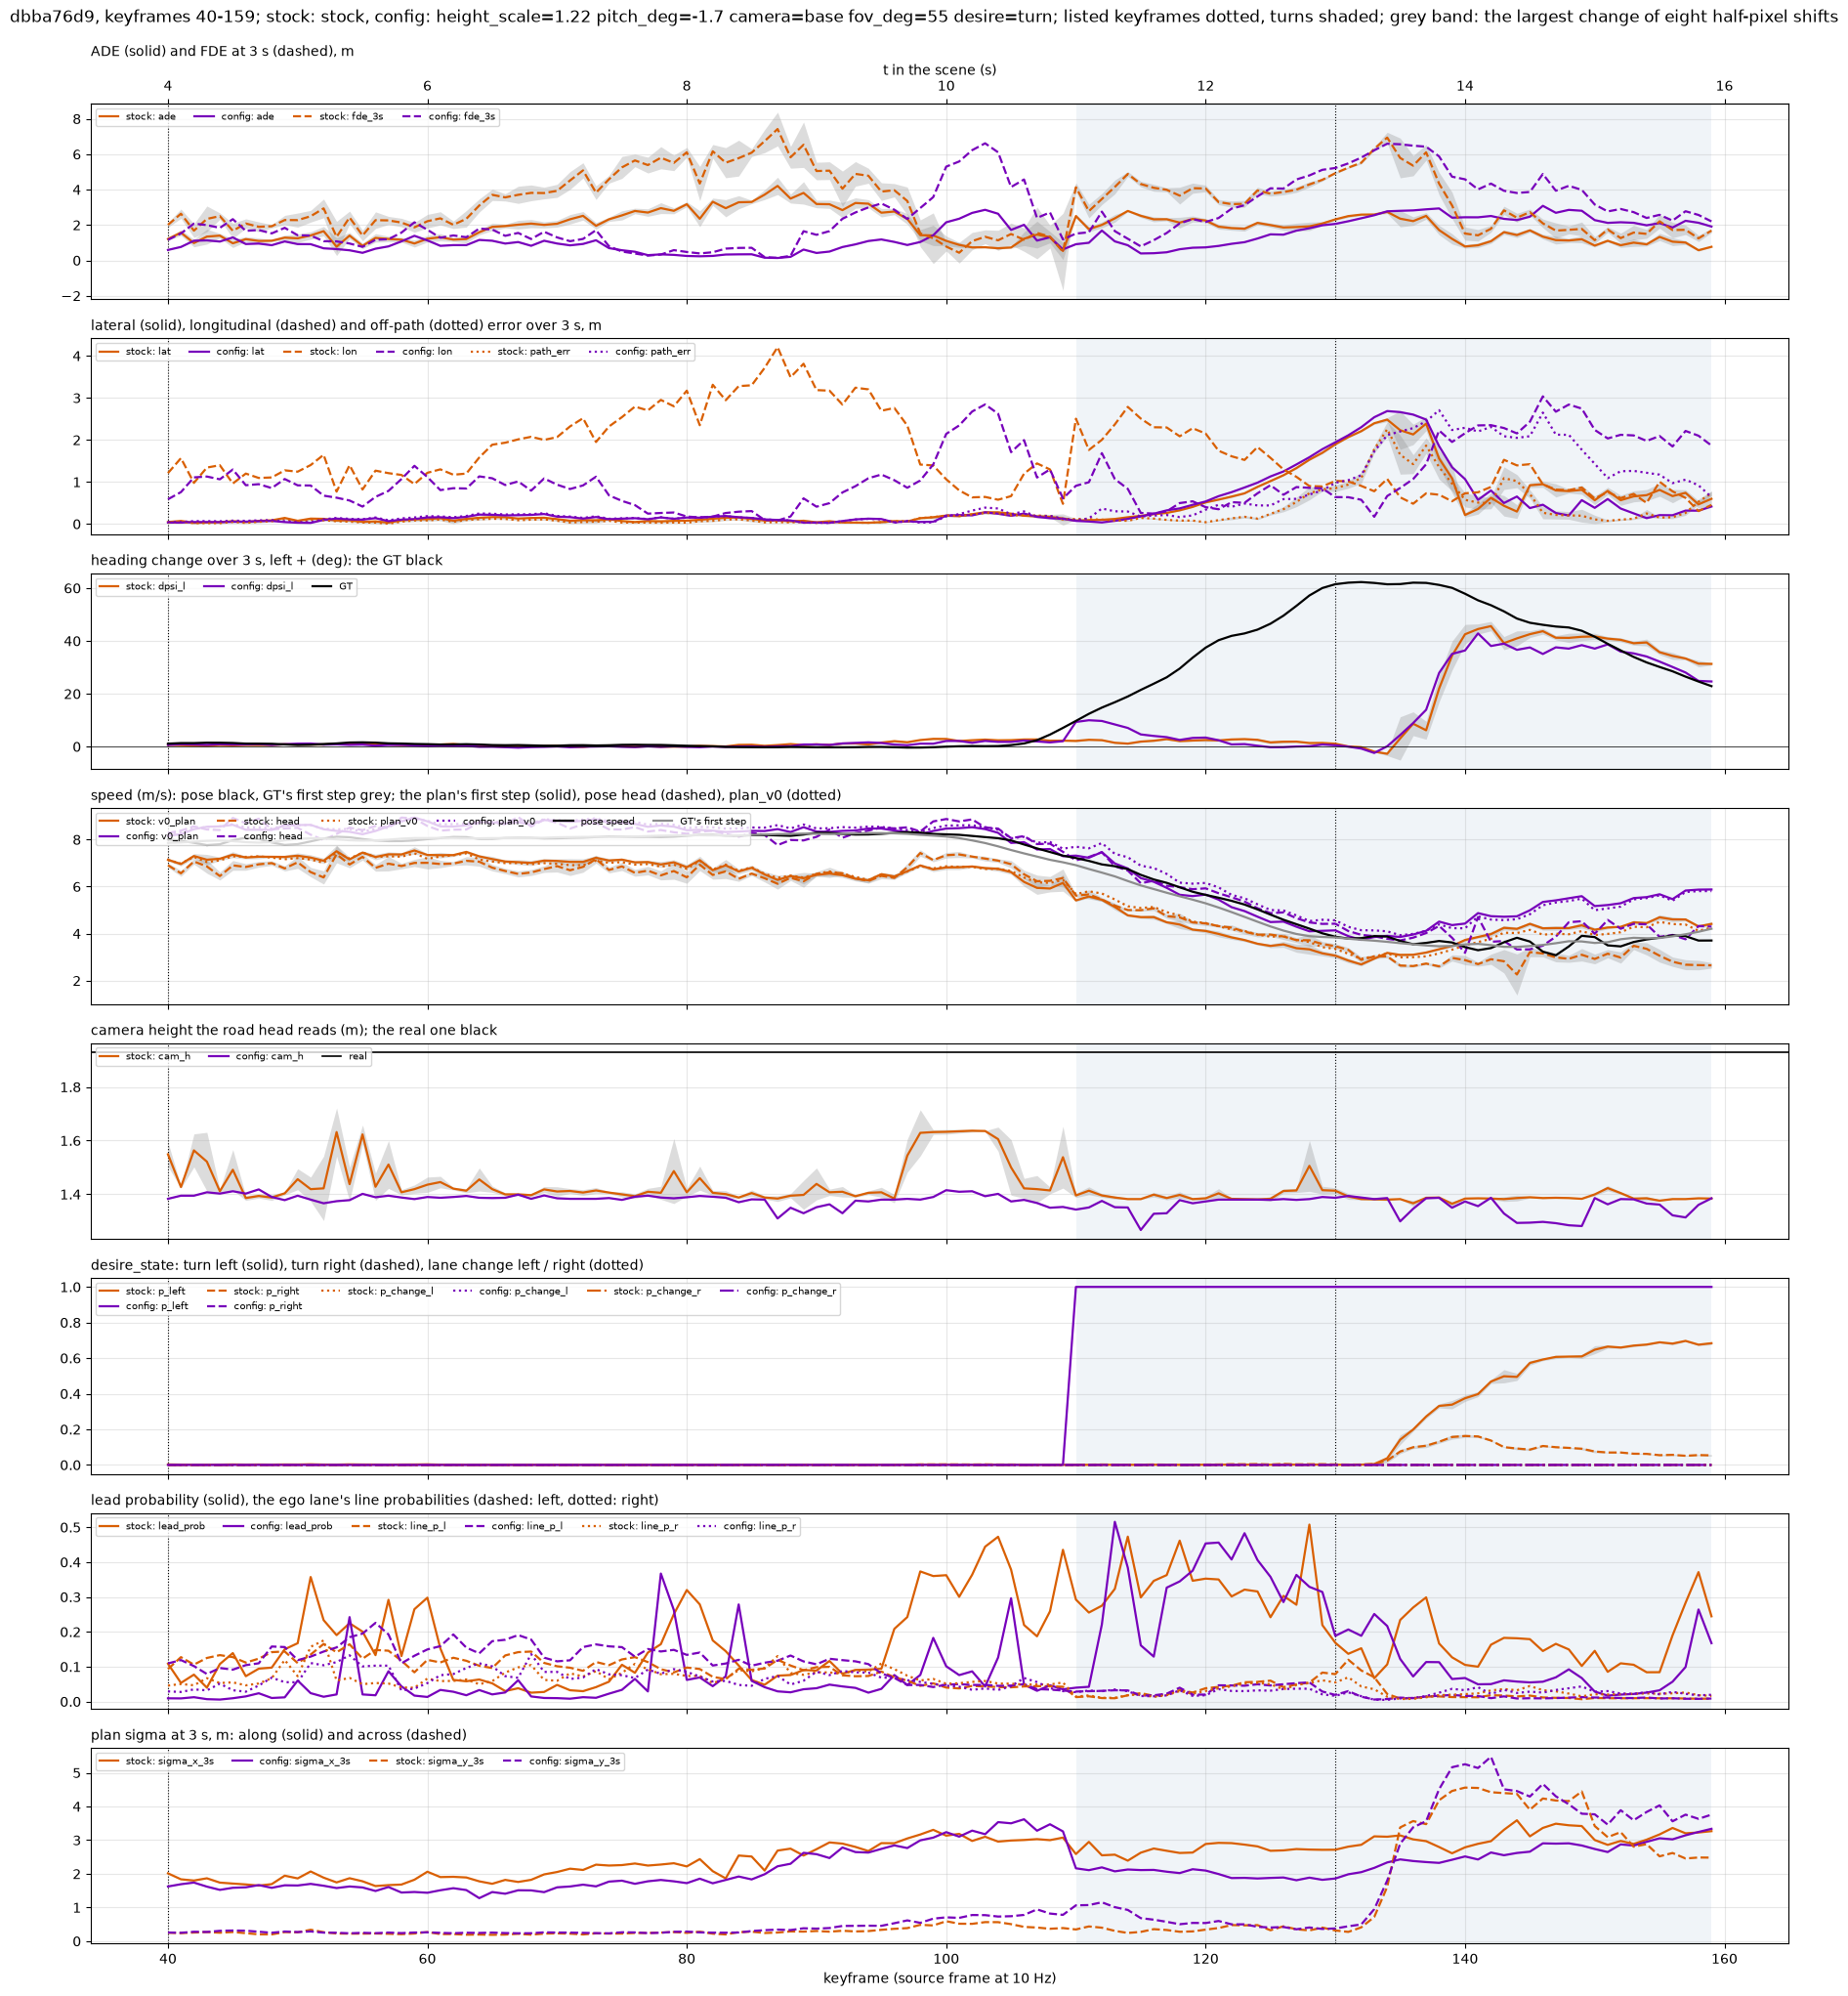

,,t_s,listed,route,side,ade,fde_3s,lat,lon,path_err,dpsi_l,v0_plan,head,plan_v0,cam_h,p_left,p_right,p_change_l,p_change_r,lead_prob,line_p_l,line_p_r,sigma_x_3s,sigma_y_3s,gt_dpsi_l,v,v0_gt,heading_err,v0_err,cam_h_err,noise_ade,noise_fde_3s,noise_lat,noise_path_err,noise_dpsi_l,noise_v0_plan,noise_head,noise_cam_h,noise_p_left,noise_p_right
k,arm,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
40,stock,4.0,True,Continue straight,straight,1.210846,2.007655,0.046282,1.209843,0.032993,0.661277,7.143024,6.910156,7.128906,1.548828,0.002850,0.001659,4.112922e-05,1.614033e-04,0.108566,0.093182,0.045863,2.014147,0.250192,1.111897,8.007374,7.861292,0.450620,0.718268,0.381772,0.074521,0.132314,0.023677,0.023580,0.132649,0.061456,0.089844,0.044922,0.000434,0.000291
41,stock,4.1,False,Continue straight,straight,1.567680,2.638006,0.071643,1.565833,0.050930,0.529675,6.958646,6.566406,6.980469,1.426758,0.001868,0.001264,3.564965e-05,1.011605e-04,0.053502,0.127435,0.050331,1.836256,0.237486,1.327577,7.949117,7.879418,0.797902,0.920771,0.503842,0.162265,0.265162,0.009476,0.009355,0.075553,0.081563,0.125000,0.003906,0.000807,0.000221
42,stock,4.2,False,Continue straight,straight,0.978324,1.680420,0.027853,0.977685,0.019281,0.410266,7.300664,7.070312,7.265625,1.563477,0.001433,0.001226,3.147124e-05,1.701319e-04,0.077239,0.105948,0.046725,1.799884,0.254449,1.328084,7.862488,7.914260,0.917818,0.613596,0.367123,0.213060,0.383348,0.023235,0.015221,0.094969,0.102831,0.113281,0.061523,0.000338,0.000215
43,stock,4.3,False,Continue straight,straight,1.342747,2.344056,0.035977,1.342012,0.019555,0.317456,7.144228,6.859375,7.042969,1.521484,0.001668,0.001475,3.816031e-05,2.007283e-04,0.039862,0.125065,0.067056,1.866400,0.269189,1.474523,7.765304,7.945771,1.157068,0.801543,0.409116,0.421166,0.728688,0.012290,0.005873,0.211798,0.225721,0.289062,0.109375,0.000517,0.000248
44,stock,4.4,False,Continue straight,straight,1.398261,2.501940,0.044519,1.397350,0.019402,0.582917,7.184421,6.449219,7.117188,1.411133,0.001790,0.001216,2.955480e-05,1.340168e-04,0.107625,0.133190,0.053206,1.738470,0.249947,1.462619,7.801772,7.959042,0.879702,0.774620,0.519467,0.128571,0.179184,0.009068,0.009556,0.176971,0.074911,0.167969,0.006836,0.000621,0.000244
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,config,15.5,False,Turn left in 22m,left,2.104960,2.575092,0.210035,2.093093,1.173330,32.173003,5.674460,3.865234,5.625000,1.361328,0.999910,0.000058,5.646229e-09,1.299836e-09,0.032344,0.008745,0.020567,3.054896,4.033036,30.146684,3.827800,3.813492,2.026320,1.860969,0.569272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
156,config,15.6,False,Turn left in 21m,left,1.856576,2.246230,0.207436,1.843872,0.971670,30.140303,5.467690,3.943359,5.398438,1.321289,0.999939,0.000041,1.362257e-09,9.811967e-10,0.056966,0.009449,0.027796,3.023690,3.559300,28.507377,3.923690,3.884437,1.632925,1.583253,0.609311,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
157,config,15.7,False,Turn left in 21m,left,2.237037,2.777663,0.318062,2.213628,1.054834,28.049052,5.832400,3.759766,5.769531,1.313477,0.999958,0.000020,5.690790e-09,1.165222e-09,0.098947,0.008031,0.022117,3.143762,3.757308,26.487384,3.892110,3.971708,1.561668,1.860692,0.617123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
plotted = lab.timeline(CONFIG, AGAINST)  # what the panels drew, one row per keyframe and arm
plotted

In [13]:
plotted["ade"].mean()

np.float64(1.589922401784512)

**Has the config improved the numbers?** `plotted` holds every value the timeline drew, one row per keyframe and arm. Its columns:

- the keyframe: `t_s`, `listed`, `route`, `side`;
- each drawn column, and the references drawn beside them: `gt_dpsi_l`, `v`, `v0_gt`;
- three errors against those references (absolute, so lower is closer):
    - `heading_err`: the plan's 3 s heading against the GT's;
    - `v0_err`: the plan's first-step speed against the GT's;
    - `cam_h_err`: the read camera height against the map's;
- `noise_<col>` on the baseline's rows.

`lab.compare(plotted)` pairs config with baseline keyframe by keyframe. For each column it gives:

- each arm's mean and median;
- the difference's mean and median, with a 95% interval for the mean;
- how many keyframes moved beyond the half-pixel noise floor, in each direction;
- a verdict: "better" or "worse" for error columns when the interval excludes 0, or "up" or "down" for the rest.

The interval comes from a moving-block bootstrap over 1 s blocks. Neighbouring keyframes share 47 of their 48 history frames, so 120 keyframes are far fewer independent samples than they look.

`ks` restricts the comparison to part of the scene, for example `slice(110, 137)` for the stretch where stock plans straight through the turn. With `CONFIG = None` the baseline is compared with itself, and every difference is 0.

In [9]:
diffs = lab.compare(plotted)  # the whole scene
diffs_turn = lab.compare(plotted, ks=slice(110, 137))  # the turn stock misses
display(diffs, diffs_turn)

config - stock, keyframes 40-159 (120); interval: 2000 moving-block bootstraps of 10 keyframes
config - stock, keyframes 110-137 (28); interval: 2000 moving-block bootstraps of 10 keyframes


,n,stock mean,config mean,stock median,config median,diff mean,diff median,95% lo,95% hi,beyond noise -,beyond noise +,verdict
column,,,,,,,,,,,,
ade,120,1.849220,1.330625,1.775610,1.072116,-0.518594,-0.364607,-1.303257,0.111450,72,33,no change shown
fde_3s,120,3.324074,2.591644,3.187867,2.160572,-0.732430,-0.525864,-2.164056,0.463228,67,43,no change shown
lat,120,0.438721,0.440007,0.148321,0.170965,0.001286,0.023208,-0.064944,0.083487,33,61,no change shown
lon,120,1.632214,1.119570,1.393135,0.918032,-0.512644,-0.406797,-1.345976,0.153929,<NA>,<NA>,no change shown
path_err,120,0.266608,0.573829,0.104609,0.190814,0.307221,0.093181,0.076895,0.582964,7,95,worse
dpsi_l,120,8.057244,7.530765,1.182041,0.867266,-0.526479,-0.281963,-1.381603,0.654072,66,25,no change shown
v0_plan,120,5.723281,7.088873,6.466423,8.304947,1.365592,1.384836,1.193296,1.564608,0,120,up
head,120,5.432829,6.885661,6.373047,8.117188,1.452832,1.541016,1.276422,1.621617,0,119,up
plan_v0,120,5.732926,7.218685,6.488281,8.414062,1.485758,1.466797,1.311240,1.685425,<NA>,<NA>,up


,n,stock mean,config mean,stock median,config median,diff mean,diff median,95% lo,95% hi,beyond noise -,beyond noise +,verdict
column,,,,,,,,,,,,
ade,28,2.233768,1.491656e+00,2.284575,1.344134e+00,-0.742112,-0.641392,-1.493900,-0.229820,21,2,better
fde_3s,28,4.425305,3.652697e+00,4.116752,3.365754e+00,-0.772608,-0.298217,-1.999226,0.273184,15,9,no change shown
lat,28,1.066513,1.151077e+00,0.805511,9.251227e-01,0.084564,0.071087,0.023909,0.118964,6,20,worse
lon,28,1.577599,7.168991e-01,1.591963,6.799237e-01,-0.860700,-0.709108,-1.612589,-0.359129,<NA>,<NA>,better
path_err,28,0.575481,7.624096e-01,0.157500,4.490927e-01,0.186928,0.125749,0.103220,0.222293,1,21,worse
dpsi_l,28,2.009023,3.414109e+00,2.123419,2.463159e+00,1.405086,0.346247,-1.273121,2.484431,11,13,no change shown
v0_plan,28,3.893801,5.157837e+00,3.648070,4.839593e+00,1.264036,1.191523,0.966391,1.537956,0,28,up
head,28,4.089355,5.298200e+00,4.020508,5.222656e+00,1.208845,1.191406,0.945871,1.396936,0,28,up
plan_v0,28,4.158133,5.572126e+00,4.036133,5.375000e+00,1.413993,1.338867,1.118753,1.687709,<NA>,<NA>,up


## 5. Every keyframe's figure, to the cache

Each keyframe's figure is drawn as `kf_<k>.jpg` into the sweep's `frames/` directory, beside `scores.csv` and `arms.json`. The directory sits under `{runs}`, keyed by scene, code and arms, so a code change or a new config never reuses stale figures. Figures that already exist are kept; pass `redo=True` after changing `OVERLAY`.

Each figure shows:

- **Top strip:** where the keyframe sits on the timeline (purple line): ADE, heading, start speed, and p(turn).
- **The camera photo** with each view's footprint, the road grid at 10–60 m, and the GT and plans.
- **BEV:** the GT and the plans over 10 s.
- **The model's own road:** lane lines (opacity is their probability), road edges, the lead, and the plan.
- **Speed and heading** per 0.5 s step, and the full **desire_state**.
- **The four model inputs** for each arm (each view at t − 0.2 s and at t), with the expected horizon lines.

In [10]:
lab.dump(CONFIG, AGAINST, overlay=OVERLAY, workers=WORKERS)

drew 0 of 120 keyframes in 0 s; {runs}/kitscenes/_analysis/openpilot/scene_sweep/dbba76d9/133d484051-412815/b3613d331a/frames


## 6. Frame by frame

Set `FRAME` and re-run the cell. It shows that keyframe's figure (from the part 5 cache, or drawn now if it is missing), then the scores of it and of the two keyframes either side, one column each, its own marked `<<`. `FRAME` takes a keyframe index, a label such as `"dbba76d9/150"`, or a sample id.

With `WIDGETS = True`, `lab.browse()` gives a slider over every keyframe instead.

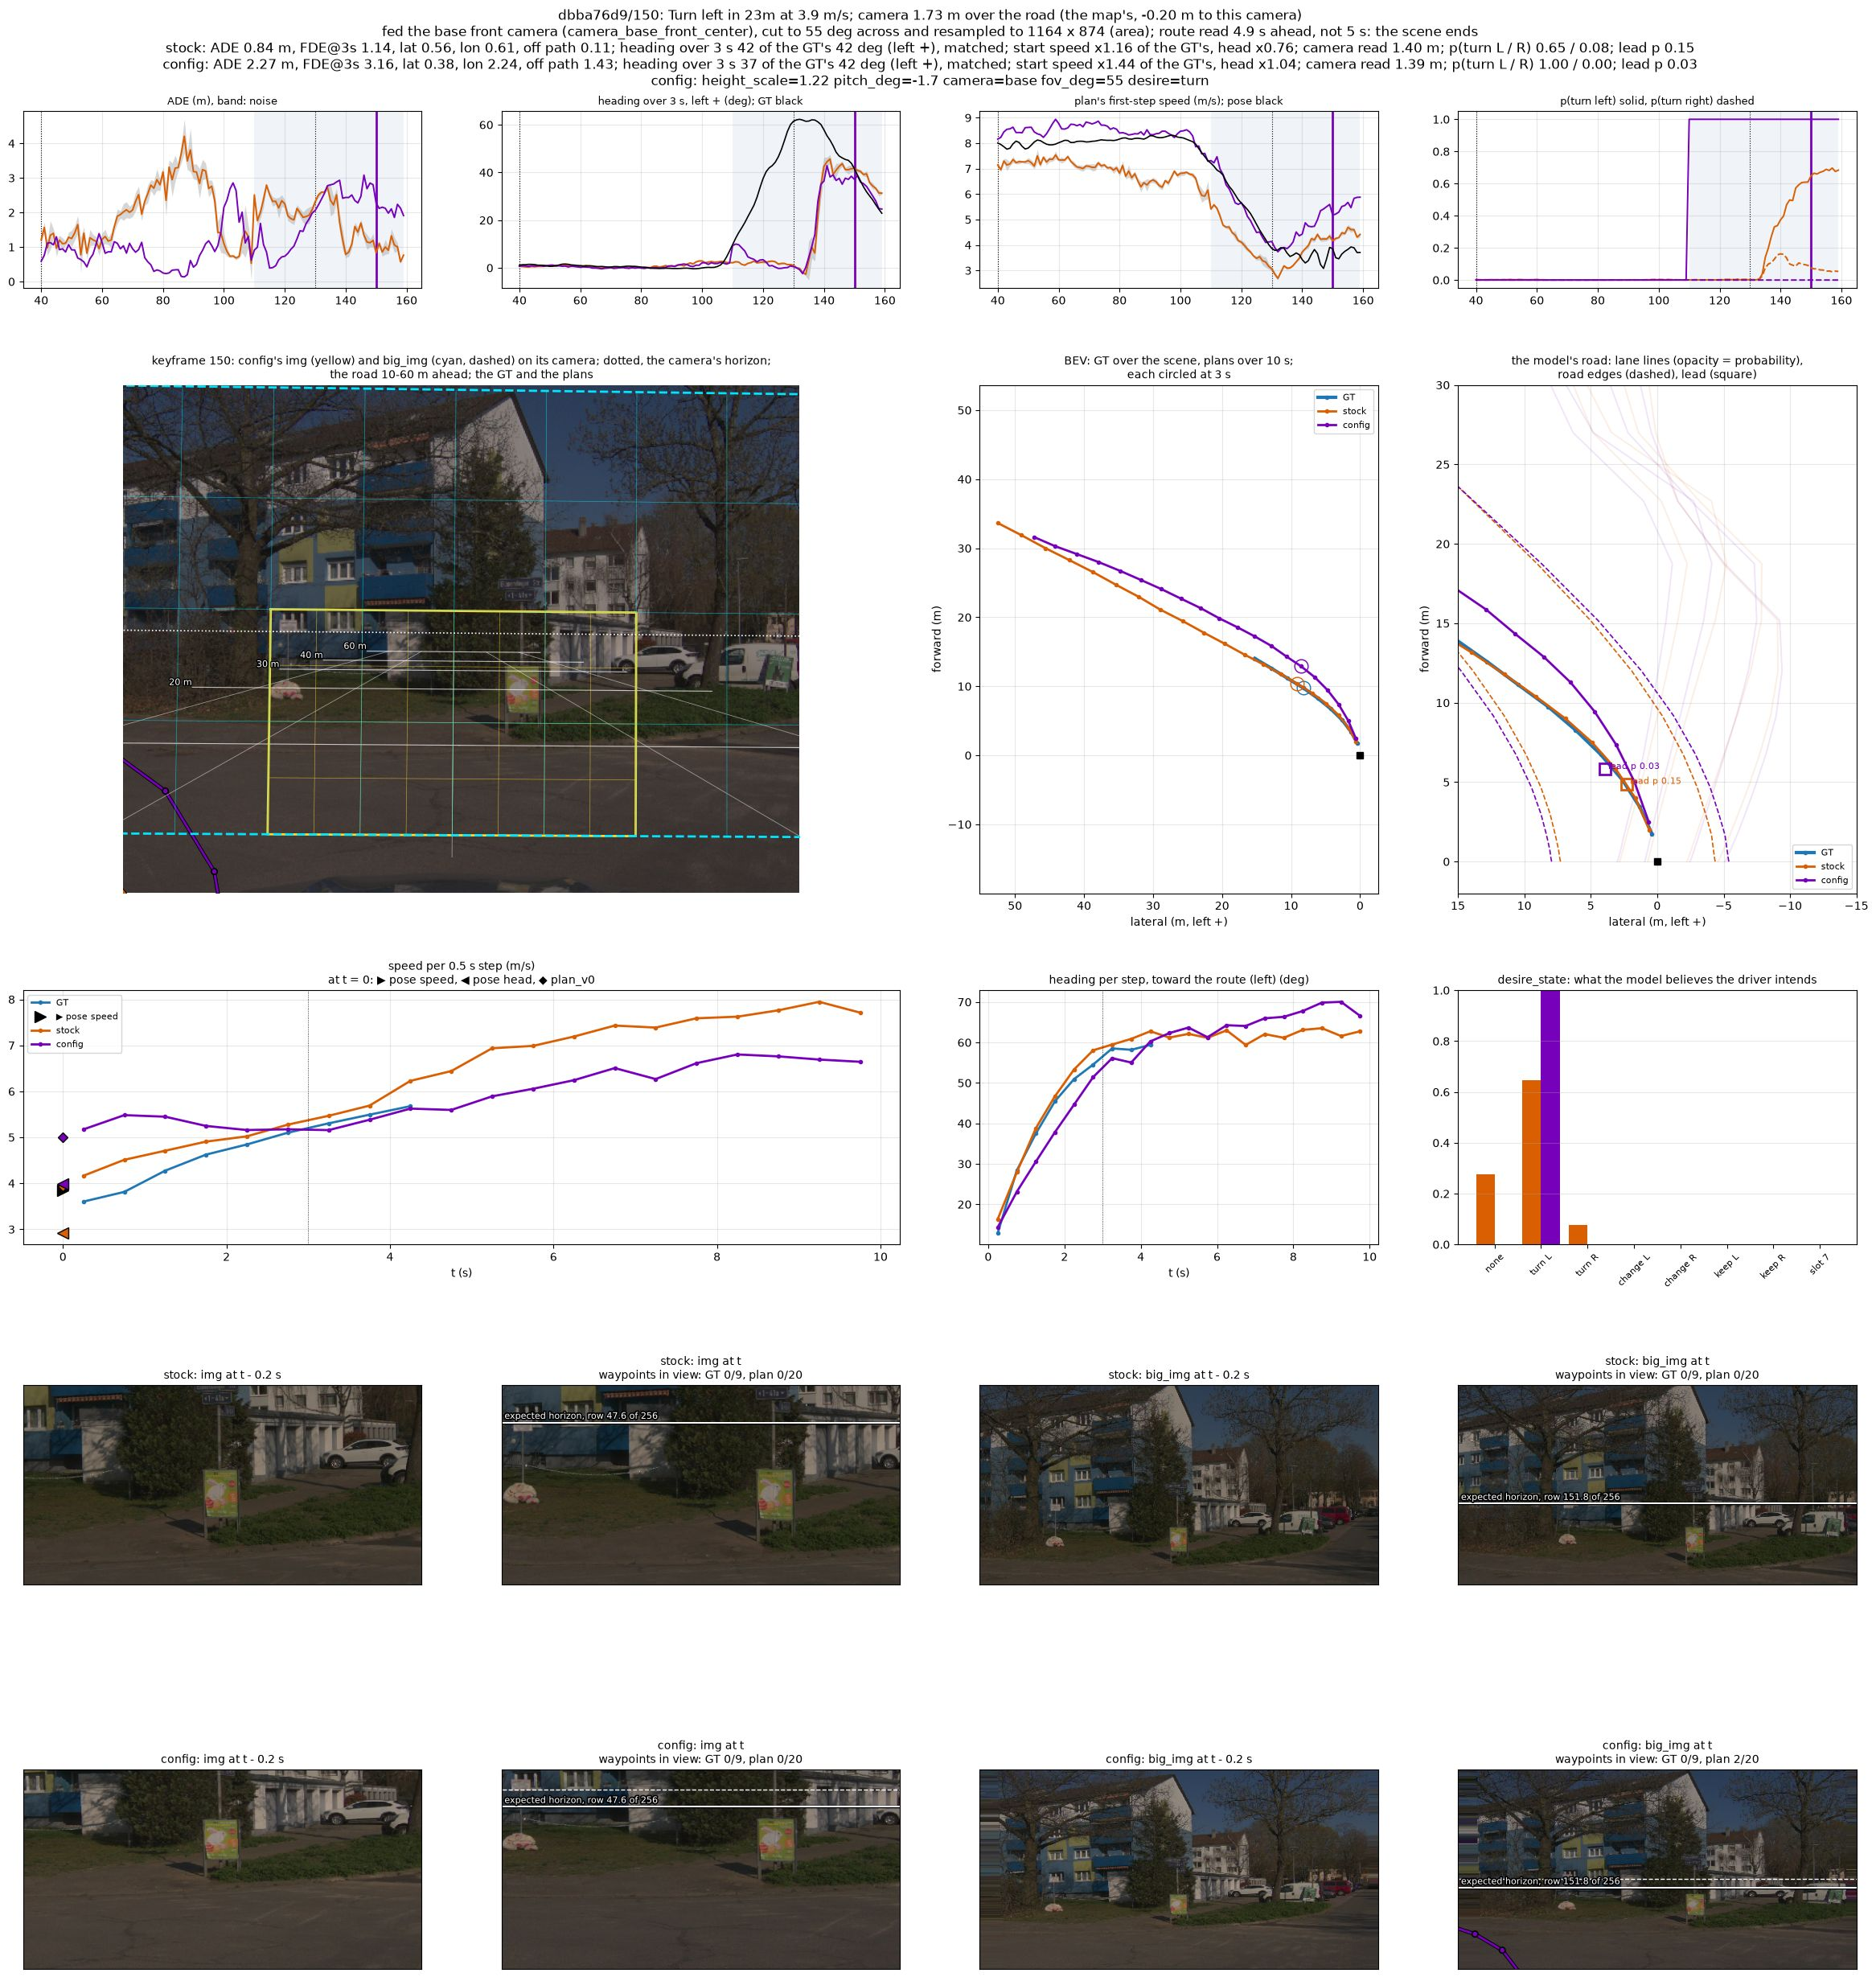

**Keyframe 150, and 2 either side**, one column each; k is marked `<<`

,148,148,149,149,150 <<,150 <<,151,151,152,152
t_s,14.8,14.8,14.9,14.9,15.0,15.0,15.1,15.1,15.2,15.2
listed,False,False,False,False,False,False,False,False,False,False
route,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m,Turn left in 23m
side,left,left,left,left,left,left,left,left,left,left
lookahead_s,5.0,5.0,5.0,5.0,4.9,4.9,4.8,4.8,4.7,4.7
v,3.455,3.455,3.907,3.907,3.853,3.853,3.5,3.5,3.456,3.456
mode,matched,matched,matched,matched,matched,matched,matched,matched,matched,matched
ade,1.125,2.854,1.194,2.805,0.837,2.274,1.108,2.12,0.855,2.154
fde_1s,0.71,1.921,0.821,1.991,0.65,1.645,0.715,1.602,0.6,1.574
fde_2s,1.365,3.459,1.424,3.386,0.995,2.733,1.279,2.549,1.01,2.591


In [11]:
FRAME = 150
lab.frame(FRAME, CONFIG, AGAINST, overlay=OVERLAY)

In [12]:
lab.browse(CONFIG, AGAINST, overlay=OVERLAY)

WIDGETS is off: set WIDGETS = True in part 1 for a slider, or call lab.frame(k) for keyframe k


## 7. What this scene shows (stock, `dbba76d9`)

Read off the cells above on 2026-10-02. Rerunning with another `SCENE`, `START` or `CONFIG` changes the numbers but not this text.

**Measured** (the score table, the scene's poses, and the figures in part 5):

- **The benchmark sees two points of a 12 s story.** It scores 40 (straight: ADE 1.21 m) and 130 (left turn, `not_planned`: ADE 2.32 m). 130 falls in the stretch where the car has slowed for the turn but not yet started it.
- **Where the car turns.** It brakes from 8.2 m/s at keyframe 105 to 3.9 m/s at 132. Its yaw only begins after that: 2.7° at 136, past 5° at 138, past 20° at 145, and about 90° by 180.
    - The 5 s route rule first calls a turn at 110. The GT's 3 s heading passes 10° at 111 and peaks at 62° over 130–134.
    - Keyframes 40–109 are "Continue straight" by the rule, but their 10 s GT already contains the turn. Keyframe 87 is the clearest example.
- **When the model turns.** Its 3 s heading stays under 3° through 134, passes 10° at 138 and 30° at 139, and is `matched` from 140 on (19 keyframes). The 28 keyframes in 110–137 are `not_planned`.
    - Its desire head shows the same timing: p(turn left) is 0.00 until 132, 0.1 at 135, 0.5 at 145, and 0.68 by 159.
    - Its lateral uncertainty at 3 s (`sigma_y_3s`) jumps from under 0.5 m to over 2 m at 135.
- **The straight stretch (40–109) is all longitudinal error.** Mean ADE is 1.92 m, of which lon is 1.91 and lat 0.11.
    - The plan's first step averages 0.87× the pose speed over 40–100.
    - ADE peaks at 4.21 m at 87. There the GT holds 8.2 m/s for 1.5 s, then brakes for the turn about 35 m ahead. The plan starts at 6.3 m/s and brakes from t = 0.
- **The camera height the road head reads** is 1.40 m (median over the 120 keyframes), against the map's 1.93 m. The same low reading appears in the image-tweak notebook.
- **Noise.** Over the 120 keyframes, the largest ADE change any half-pixel shift makes has a median of 0.18 m. It is under 0.3 m on 86% of keyframes and at most 0.76 m (keyframe 107). The straight-stretch hump (up to 4.2 m) and the turn's errors are well above it; single-keyframe wiggles of under 0.5 m are not.

**Argued, not tested:**

- **The model follows this turn; it does not anticipate it.** Its plan and its desire head both move within about 0.3 s of the car's own yaw starting, and neither moves before it. Over 110–134 the intersection is in view, the car is braking hard, and the model's own road edges (part 5's "model's road" panel at 134) already bend left, yet the plan stays straight.
    - That fits a model that reads the turn from frame-to-frame motion in its 4.8 s of history, rather than from the road layout.
    - A `CONFIG` with `desire="turn"` swept over 110–137 is the test. It would show whether being told the turn moves the plan earlier.
- **Most of the error before the turn comes from the start speed, not from the path.** The plan starts slow on every keyframe, and the gap grows where the human holds speed into a late, hard brake (80–95). That matches the earlier finding that ADE is mostly start speed.